In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('../Kinematics'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
from FK_Multi import FK_Multi
GRID = False
FONT_SIZE = 24
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

# Gaussian Repulsion — Fixed Obstacle

`fixed_gauss5.npz` — a fixed Gaussian obstacle sits on the arm body (`gauss_seg1` at
s=0.333, `gauss_seg2` at s=0.667) while a tip spring (`lin_seg3`) pulls toward a fixed
target. The repulsive field is switched off mid-run.

**Goal:** compare the backbone posture (x-z plane) averaged over the 5 s immediately
before the field is removed (obstacle active) against the 5 s immediately after
(obstacle removed), to show how much the Gaussian pushes the arm off its direct path
to the target.

## Force law

`GaussianSpring.compute_force` (`VMC_utils/VirtualModels.py`) implements

$$F = A \, e^{-\frac{\lVert \Delta \rVert^2}{2\sigma^2}} \, \Delta, \qquad \Delta = x_{current} - x_{obstacle}$$

with $A$ = `strength` (force amplitude, N) and $\sigma$ = `sigma` (spread, m) — these
are exactly the "strength" and $\sigma$ values printed in the legend below (Gauss seg 1:
$A=240$ N, Gauss seg 2: $A=200$ N, both $\sigma=0.06$ m).

- **At the obstacle** ($\Delta \to 0$): the force also goes to zero — despite peaking
  nearby, there's no singularity/discontinuity right at the source.
- **Peak repulsion** occurs at $\lVert \Delta \rVert = \sigma$ (one "spread" away from
  the obstacle), where the force magnitude is maximized before decaying again.
- **Far away** ($\lVert \Delta \rVert \gg \sigma$): the Gaussian term vanishes, so the
  repulsion has essentially no effect far from the obstacle — unlike an inverse-square
  law, it doesn't reach out indefinitely.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load('outputs/fixed_gauss/fixed_gauss5.npz', allow_pickle=True)
t         = d['t']
k_params  = d['k_params']    # (n, 3)  — [lin_seg3, gauss_seg1, gauss_seg2]
comp_pos  = d['comp_pos'] * 100.0  # (n, 3, 3) — FK x/y/z at each VC s_param [m -> cm]
q_motor   = d['q_motor']     # (n, 9) — motor angles, for the dense PCC curve
goal      = d['goal'] * 100.0      # (n, 3, 3) — reference positions [m -> cm]
names     = [str(s) for s in d['comp_names']]
s_params  = list(d['comp_s_params'])

print('Components:', list(zip(names, [f's={s:.3f}' for s in s_params])))
print('Duration:  ', f'{t[-1]:.1f} s')

# Find the gaussian strength drop to zero
gauss_k  = k_params[:, 1]
diff_k   = np.diff(gauss_k)
drop_idx = int(np.where(diff_k < -50)[0][0])
drop_t   = t[drop_idx]
print(f'\nGauss strength drop at t = {drop_t:.2f} s  (idx={drop_idx})')
print(f'  k before: gauss1={k_params[drop_idx, 1]:.0f}  gauss2={k_params[drop_idx, 2]:.0f}')
print(f'  k after:  gauss1={k_params[drop_idx+1, 1]:.0f}  gauss2={k_params[drop_idx+1, 2]:.0f}')

WIN = 5.0
mask_before = (t >= drop_t - WIN) & (t < drop_t)
mask_after  = (t >  drop_t)       & (t <= drop_t + WIN)
print(f'\nBefore window: {mask_before.sum()} samples  [{t[mask_before][0]:.2f}, {t[mask_before][-1]:.2f}] s')
print(f'After  window: {mask_after.sum()} samples  [{t[mask_after][0]:.2f}, {t[mask_after][-1]:.2f}] s')

Components: [('lin_seg3', 's=1.000'), ('gauss_seg1', 's=0.333'), ('gauss_seg2', 's=0.667')]
Duration:   63.9 s

Gauss strength drop at t = 53.40 s  (idx=16598)
  k before: gauss1=233  gauss2=200
  k after:  gauss1=0  gauss2=0

Before window: 1649 samples  [48.40, 53.39] s
After  window: 649 samples  [56.43, 58.40] s


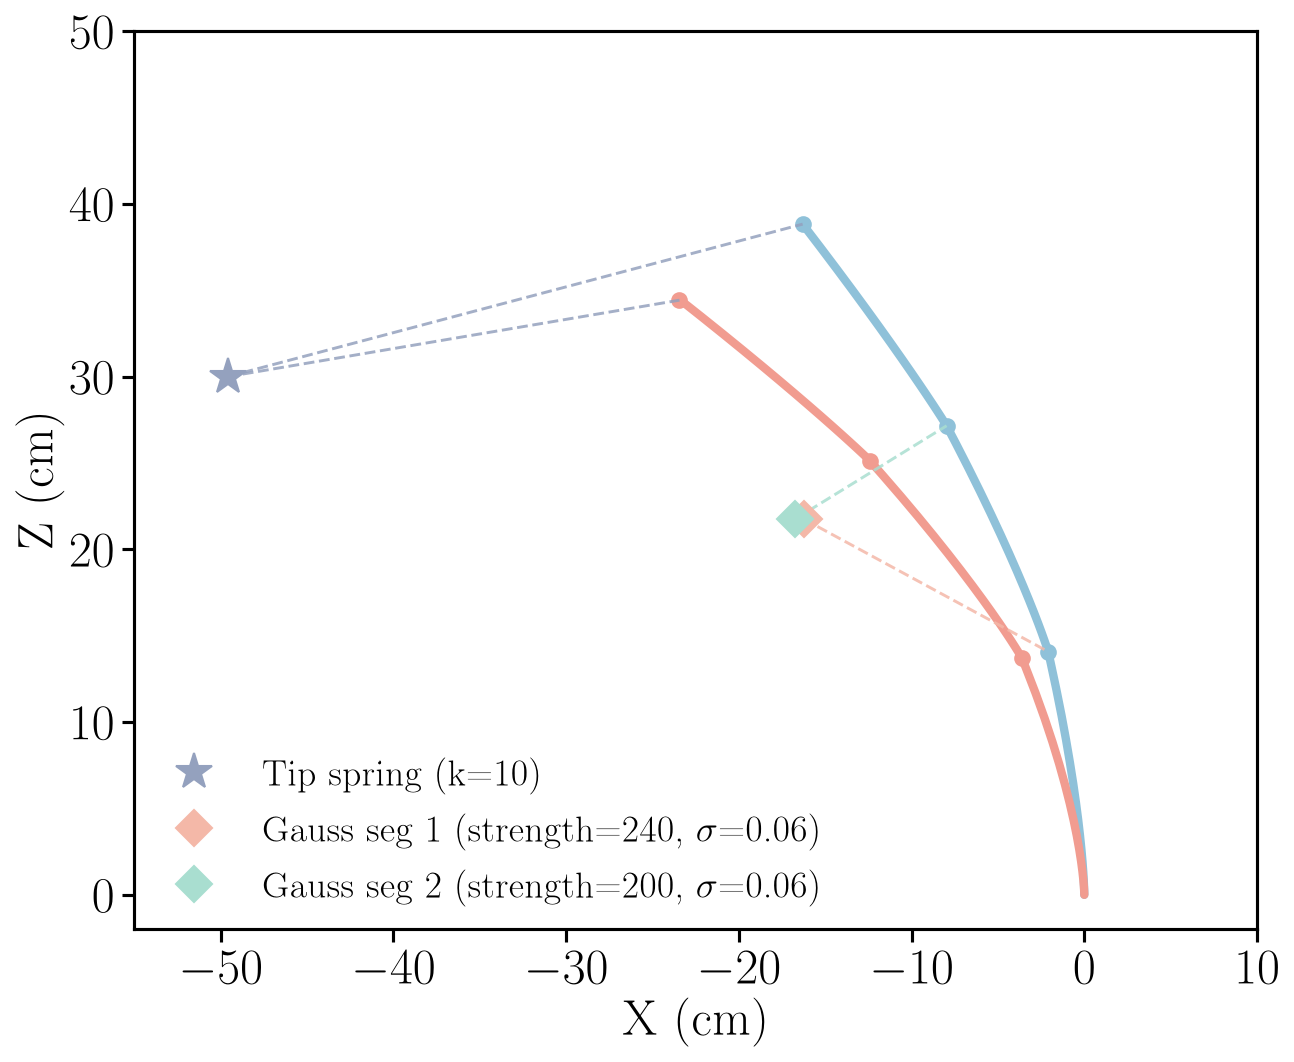

Saved -> outputs\fixed_gauss\fixed_gauss5_xz.pdf


In [3]:
# X-Z plane visualisation: before (blue) and after (red) — postures only
SHOW_SPRINGS = True   # dashed lines from each spring's goal to its attach point

# Shared NPG palette: navy/coral/light-teal for the three springs, blue/red for
# before/after -- keeps this figure in the same family as the rest of the repo.
VC_COLORS   = [COLORS[3], COLORS[4], COLORS[6]]  # tip spring, gauss1, gauss2
C_BEFORE    = COLORS[0]   # blue — obstacle active
C_AFTER     = COLORS[1]   # red  — obstacle removed
BACKBONE_LW = 4.0
S_DENSE = np.linspace(0.0, 1.0, 50)

# ---- size / aspect for THIS graph only ----
W_IN   = 9.0     # inches -- width; the deliberate choice, so the fixed 18pt font
                 # (set_font_size) reads at the intended size once this is fixed
ASPECT = 8 / 9   # height/width -- near-square, room for the legend + geometry
H_IN   = W_IN * ASPECT

# Representative postures: mean position over each window
pose_before = comp_pos[mask_before].mean(axis=0)   # (3, 3)  [tip, g1, g2] x/y/z
pose_after  = comp_pos[mask_after].mean(axis=0)    # (3, 3)
gl_active   = goal[mask_before]                    # (m, 3, 3)
q_before    = q_motor[mask_before].mean(axis=0)    # (9,) for the dense PCC curve
q_after     = q_motor[mask_after].mean(axis=0)

# Attach points (where the springs connect) — use the active (before) posture
attach_active = pose_before                        # (3, 3)

fig, ax = plt.subplots(figsize=(W_IN, H_IN))

# ── Two backbones only: before (blue) and after (red) ─────────────────────────
# The true continuous PCC shape, not just the 3 named attachment points joined
# by straight segments. FK_Multi returns metres -- scale to cm to match comp_pos/goal.
for q, color in [(q_before, C_BEFORE), (q_after, C_AFTER)]:
    curve = np.array([FK_Multi(q, s)[:3] for s in S_DENSE]) * 100.0
    curve = np.vstack([[0.0, 0.0, 0.0], curve])
    ax.plot(curve[:, 0], curve[:, 2], '-', color=color, linewidth=BACKBONE_LW,
            solid_capstyle='round', zorder=3)
for pose, color in [(pose_before, C_BEFORE), (pose_after, C_AFTER)]:
    ax.plot(pose[:, 0], pose[:, 2], 'o', color=color, markersize=7, zorder=4)

if SHOW_SPRINGS:
    # ── Linear spring: dashed connectors ref(star) -> tip, for BEFORE and AFTER ──
    lin_gx, lin_gz = float(gl_active[-1, 0, 0]), float(gl_active[-1, 0, 2])
    ax.plot([lin_gx, pose_before[0, 0]], [lin_gz, pose_before[0, 2]],
            '--', color=VC_COLORS[0], linewidth=1.4, alpha=0.85, zorder=4)
    ax.plot([lin_gx, pose_after[0, 0]], [lin_gz, pose_after[0, 2]],
            '--', color=VC_COLORS[0], linewidth=1.4, alpha=0.85, zorder=4)
    lin_k = float(k_params[mask_before][0, 0])
    ax.plot(lin_gx, lin_gz, '*', color=VC_COLORS[0], markersize=18, zorder=5,
            label=f'Tip spring (k={lin_k:.0f})')

    # ── Gaussian springs: dashed connector ref(diamond) -> attach, + diamond ─────
    for vc_i, color, prefix in [(1, VC_COLORS[1], 'Gauss seg 1'),
                                (2, VC_COLORS[2], 'Gauss seg 2')]:
        gx, gz = float(gl_active[0, vc_i, 0]), float(gl_active[0, vc_i, 2])
        ax.plot([gx, attach_active[vc_i, 0]], [gz, attach_active[vc_i, 2]],
                '--', color=color, linewidth=1.4, alpha=0.85, zorder=4)
        k_val = float(k_params[mask_before][0, vc_i])
        ax.plot(gx, gz, 'D', color=color, markersize=12, zorder=5,
                label=f'{prefix} (strength={round(k_val/20)*20:.0f}, σ=0.06)')

# ── Legend: spring markers only -- no blue/red before/after key ──────────────
ax.legend(loc='lower left', framealpha=0.92)

ax.set_xlabel('X (cm)')
ax.set_ylabel('Z (cm)')
ax.grid(GRID)
ax.set_xlim(-55, 10)
ax.set_ylim(-2, 50)
ax.set_aspect('equal')

plt.tight_layout()
out = os.path.join('outputs', 'fixed_gauss', 'fixed_gauss5_xz.pdf')
plt.savefig(out)
plt.show()
print(f'Saved -> {out}')